# Ohshima (1987) linear stability solver, nondimensionalized with `U0` and `Ljet`

Strip-method solver (Ohshima 1987, Appendices A and B) for the linear stability of a barotropic jet
over a sloping bottom, using the jet speed $U_0$ and half shear width $L_{jet}$ as the velocity and
length scales (Eq. 3 of the manuscript).

**Nondimensional stability equation**

$$Ro\,(\hat\sigma+\hat v\hat k)\left[\left(\frac{\hat\varphi'}{\hat h}\right)'-\frac{\hat k^2}{\hat h}\hat\varphi\right]
- \hat k\,\hat P'\,\hat\varphi = 0,
\qquad
\hat P = \frac{1+Ro\,\hat v'}{\hat h},\qquad
Ro = \frac{U_0}{f\,L_{jet}}$$

with $x = L_{jet}\hat x$, $t = (L_{jet}/U_0)\,\hat t$, $v = U_0\hat v$, $h = H_{max}\hat h$,
$\sigma = (U_0/L_{jet})\,\hat\sigma$, $k = \hat k/L_{jet}$.

**Contents**

| Part | What it does |
|---|---|
| 1 | Solver implementation |
| 2 | Validation against Ohshima's published eigenvalues |
| 3 | Flat bottom: check that $\hat\sigma$ is independent of $Ro$, and cross-validation against `03_dickinson_clare_solver.ipynb` |

---
# Part 1 -- Solver implementation

Profiles (nondimensional, $\hat L_{jet}=1$):

$$\hat v(\hat x) = \tfrac12\tanh(\hat x-\hat X_j),\qquad
\hat h(\hat x) = \hat h_s + \tfrac12(1-\hat h_s)\left[\tanh\!\left(\frac{2\tanh^{-1}(0.95)\,(\hat x-\hat X_s)}{\hat W}\right)+1\right]$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eig

ARCTANH95 = np.arctanh(0.95)
F_CORIOLIS = 1e-5   # s^-1

### 1.1 Profiles

In [1]:
def v_jet_shape(x, Xj_nd, Ljet_nd=1.0):
    """v_hat(x) = tanh(x)/2, ranges [-1/2,+1/2]. All jet-strength information
    lives in Ro, applied explicitly in the solver."""
    x = np.asarray(x, dtype=float)
    return 0.5 * np.tanh((x - Xj_nd) / Ljet_nd)

def vp_jet_shape(x, Xj_nd, Ljet_nd=1.0):
    """d(shape)/dx -- analytic derivative of v_hat = tanh(x)/2."""
    x = np.asarray(x, dtype=float)
    return 0.5 * (1.0 / Ljet_nd) / np.cosh((x - Xj_nd) / Ljet_nd)**2

def h_tanh(x, hs_nd, Xs_nd, Ws_nd=1.0):
    x = np.asarray(x, dtype=float)
    arg = 2 * ARCTANH95 * (x - Xs_nd) / Ws_nd
    return hs_nd + 0.5 * (1.0 - hs_nd) * (np.tanh(arg) + 1.0)

def domain_bounds(Xj_nd, Ljet_nd, Xs_nd, jet_mult=4.0, Ws_nd=1.0):
    x_min = min(Xs_nd - 0.5 * Ws_nd, Xj_nd - jet_mult * Ljet_nd)
    x_max = max(Xs_nd + 0.5 * Ws_nd, Xj_nd + jet_mult * Ljet_nd)
    return x_min, x_max

### 1.2 Generalized eigenvalue problem

The domain is split into strips with constant $\hat h$ and $\hat v'$; in each strip
$\hat\varphi = A e^{\hat k\hat x}+B e^{-\hat k\hat x}$. Continuity of $\hat\varphi$ and of
$Ro(\hat\sigma+\hat v\hat k)[\hat\varphi'/\hat h] - \hat k[\hat P\hat\varphi]$ at every strip boundary
gives $\mathbf{B}\mathbf{P}=\hat\sigma\mathbf{D}\mathbf{P}$, solved for $\hat\sigma$; growth rate $=\mathrm{Im}\,\hat\sigma$.

In [3]:
def build_and_solve_general(k, Ro, Xj_nd, hs_nd, Xs_nd, Ljet_nd=1.0, N=200, jet_mult=4.0, Ws_nd=1.0):
    x_min, x_max = domain_bounds(Xj_nd, Ljet_nd, Xs_nd, jet_mult=jet_mult, Ws_nd=Ws_nd)
    xnode = np.linspace(x_min, x_max, N + 1)
    vnode = v_jet_shape(xnode, Xj_nd, Ljet_nd)            # tanh(x)/2 shape
    xmid = 0.5 * (xnode[:-1] + xnode[1:])
    h_strip = h_tanh(xmid, hs_nd, Xs_nd, Ws_nd)
    dx = (x_max - x_min) / N
    vp_shape_strip = (vnode[1:] - vnode[:-1]) / dx         # d(shape)/dx

    h_out_L, vp_out_L = h_tanh(np.array([x_min]), hs_nd, Xs_nd, Ws_nd)[0], 0.0
    h_out_R, vp_out_R = h_tanh(np.array([x_max]), hs_nd, Xs_nd, Ws_nd)[0], 0.0

    unknowns = []
    def add_unknown(name):
        unknowns.append(name); return len(unknowns) - 1

    regions = []
    idxA0 = add_unknown("A0")
    regions.append(dict(kind="outerleft", h=h_out_L, vp=vp_out_L, coefs={"A": idxA0}, anchor=x_min))
    idxA1 = add_unknown("A1"); idxB1 = add_unknown("B1")
    regions.append(dict(kind="interior", h=h_strip[0], vp=vp_shape_strip[0],
                         coefs={"A": idxA1, "B": idxB1}, xL=xnode[0]))
    for i in range(2, N + 1):
        idxA = add_unknown(f"A{i}"); idxB = add_unknown(f"B{i}")
        regions.append(dict(kind="interior", h=h_strip[i - 1], vp=vp_shape_strip[i - 1],
                             coefs={"A": idxA, "B": idxB}, xL=xnode[i - 1]))
    idxBout = add_unknown(f"B{N+1}")
    regions.append(dict(kind="outerright", h=h_out_R, vp=vp_out_R, coefs={"B": idxBout}, anchor=x_max))
    Nu = len(unknowns)

    def basis_rows(region, x):
        val = np.zeros(Nu, dtype=complex); der = np.zeros(Nu, dtype=complex)
        kind = region["kind"]; c = region["coefs"]
        if kind == "outerleft":
            iA = c["A"]; a = region["anchor"]
            e = np.exp(k * (x - a)); val[iA] = e; der[iA] = k * e
        elif kind == "outerright":
            iB = c["B"]; a = region["anchor"]
            e = np.exp(-k * (x - a)); val[iB] = e; der[iB] = -k * e
        else:
            iA, iB = c["A"], c["B"]; xL = region["xL"]
            ep = np.exp(k * (x - xL)); em = np.exp(-k * (x - xL))
            val[iA] = ep; val[iB] = em
            der[iA] = k * ep; der[iB] = -k * em
        return val, der

    matches = [(xnode[0], regions[0], regions[1], vnode[0])]
    matches += [(xnode[j], regions[j], regions[j + 1], vnode[j]) for j in range(1, N + 1)]

    B = np.zeros((Nu, Nu), dtype=complex); D = np.zeros((Nu, Nu), dtype=complex)
    row = 0
    for (x_j, Lreg, Rreg, v_j) in matches:
        valL, derL = basis_rows(Lreg, x_j); valR, derR = basis_rows(Rreg, x_j)
        hL, hR = Lreg["h"], Rreg["h"]
        PL = (1.0 + Ro * Lreg["vp"]) / hL
        PR = (1.0 + Ro * Rreg["vp"]) / hR
        B[row, :] = valR - valL; D[row, :] = 0.0; row += 1
        jump_hinv_der = derR / hR - derL / hL
        jump_Pphi = PR * valR - PL * valL
        D[row, :] = Ro * jump_hinv_der
        B[row, :] = Ro * v_j * k * jump_hinv_der - k * jump_Pphi
        row += 1
    assert row == Nu, (row, Nu)
    ev = eig(B, D, right=False)
    return ev[np.isfinite(ev)]

def unstable_modes_general(k, Ro, Xj_nd, hs_nd, Xs_nd, Ljet_nd=1.0, N=200, jet_mult=4.0,
                            Ws_nd=1.0, imag_tol=1e-6, sanity_bound=10.0):
    sig = build_and_solve_general(k, Ro, Xj_nd, hs_nd, Xs_nd, Ljet_nd=Ljet_nd, N=N,
                                   jet_mult=jet_mult, Ws_nd=Ws_nd)
    sig = sig[np.abs(sig) < sanity_bound]
    unstable = sig[sig.imag > imag_tol]
    return unstable[np.argsort(-unstable.imag)]

def growth_rate_general(k, Ro, Xj_nd, hs_nd, Xs_nd, Ljet_nd=1.0, N=200, jet_mult=4.0, Ws_nd=1.0):
    m = unstable_modes_general(k, Ro, Xj_nd, hs_nd, Xs_nd, Ljet_nd=Ljet_nd, N=N,
                                jet_mult=jet_mult, Ws_nd=Ws_nd)
    return m[0].imag if m.size else 0.0

def strips_for_dx(x_min, x_max, dx=0.06, N_cap=300):
    N = int(round((x_max - x_min) / dx))
    return max(30, min(N, N_cap))

def growth_curve_general(k_values, Ro, Xj_nd, hs_nd, Xs_nd, Ljet_nd=1.0, dx=0.06, jet_mult=4.0, Ws_nd=1.0):
    x_min, x_max = domain_bounds(Xj_nd, Ljet_nd, Xs_nd, jet_mult=jet_mult, Ws_nd=Ws_nd)
    N = strips_for_dx(x_min, x_max, dx=dx)
    return np.array([growth_rate_general(k, Ro, Xj_nd, hs_nd, Xs_nd, Ljet_nd=Ljet_nd, N=N,
                                          jet_mult=jet_mult, Ws_nd=Ws_nd) for k in k_values])

---
# Part 2 -- Validation against Ohshima's published eigenvalues

With $U_0 = R_0 f L$ and $L_{jet}=L$, $\hat\sigma_{paper} = Ro\,\hat\sigma$. The equation is solved with
an amplitude-1 jet shape (Ohshima's Eq. 9), $Ro = R_0$, and a wall at $x=0$, and compared with the
eigenvalues given for Ohshima's Fig. 3.

In [4]:
def v_symmetric_shape(x):
    """Eq. (9) shape, amplitude 1 (paper's v = R0 * this)."""
    x = np.asarray(x, dtype=float)
    v = np.zeros_like(x)
    m = (x >= 0) & (x <= 1)
    v[m] = 0.5 * (1 - np.cos(2 * np.pi * x[m]))
    return v

def h_linear_paper(x, h0):
    x = np.asarray(x, dtype=float)
    h = np.empty_like(x)
    h[x < 0] = h0
    m = (x >= 0) & (x <= 1)
    h[m] = (1 - h0) * x[m] + h0
    h[x > 1] = 1.0
    return h

def build_and_solve_paper_general(k, Ro, h0, N=30):
    xnode = np.linspace(0.0, 1.0, N + 1)
    vnode = v_symmetric_shape(xnode)                     # amplitude 1
    xmid = 0.5 * (xnode[:-1] + xnode[1:])
    h_strip = h_linear_paper(xmid, h0)
    vp_shape_strip = (vnode[1:] - vnode[:-1]) * N
    h_out_right, vp_out_right = 1.0, 0.0

    unknowns = []
    def add_unknown(name):
        unknowns.append(name); return len(unknowns) - 1

    regions = []
    idxA1 = add_unknown("A1")
    regions.append(dict(kind="wall", h=h_strip[0], vp=vp_shape_strip[0], coefs={"A": idxA1}))
    for i in range(2, N + 1):
        idxA = add_unknown(f"A{i}"); idxB = add_unknown(f"B{i}")
        regions.append(dict(kind="interior", h=h_strip[i - 1], vp=vp_shape_strip[i - 1],
                             coefs={"A": idxA, "B": idxB}))
    idxBout = add_unknown(f"B{N+1}")
    regions.append(dict(kind="outerright", h=h_out_right, vp=vp_out_right, coefs={"B": idxBout}))
    Nu = len(unknowns)

    def basis_rows(region, x):
        val = np.zeros(Nu, dtype=complex); der = np.zeros(Nu, dtype=complex)
        kind = region["kind"]; c = region["coefs"]
        if kind == "wall":
            iA = c["A"]; val[iA] = np.sinh(k * x); der[iA] = k * np.cosh(k * x)
        elif kind == "outerright":
            iB = c["B"]; val[iB] = np.exp(-k * (x - 1.0)); der[iB] = -k * np.exp(-k * (x - 1.0))
        else:
            iA, iB = c["A"], c["B"]
            val[iA] = np.exp(k * x); val[iB] = np.exp(-k * x)
            der[iA] = k * np.exp(k * x); der[iB] = -k * np.exp(-k * x)
        return val, der

    matches = [(xnode[j], regions[j - 1], regions[j], vnode[j]) for j in range(1, N + 1)]
    B = np.zeros((Nu, Nu), dtype=complex); D = np.zeros((Nu, Nu), dtype=complex)
    row = 0
    for (x_j, Lreg, Rreg, v_j) in matches:
        valL, derL = basis_rows(Lreg, x_j); valR, derR = basis_rows(Rreg, x_j)
        hL, hR = Lreg["h"], Rreg["h"]
        PL = (1.0 + Ro * Lreg["vp"]) / hL
        PR = (1.0 + Ro * Rreg["vp"]) / hR
        B[row, :] = valR - valL; D[row, :] = 0.0; row += 1
        jump_hinv_der = derR / hR - derL / hL
        jump_Pphi = PR * valR - PL * valL
        D[row, :] = Ro * jump_hinv_der
        B[row, :] = Ro * v_j * k * jump_hinv_der - k * jump_Pphi
        row += 1
    ev = eig(B, D, right=False)
    return ev[np.isfinite(ev)]

def unstable_modes_paper_general(k, Ro, h0, N=30, imag_tol=1e-6):
    sig = build_and_solve_paper_general(k, Ro, h0, N=N)
    unstable = sig[sig.imag > imag_tol]
    return unstable[np.argsort(-unstable.imag)]

targets = [
    (1.8, 0.2, 1.0, "Ab", -0.20566, 0.04124),
    (3.6, 0.2, 1.0, "Sb", -0.28791, 0.10887),
]
print(f"{'mode':4s} {'k':>4s} {'sigma_r(paper)':>15s} {'sigma_r(here)':>15s} "
      f"{'sigma_i(paper)':>15s} {'sigma_i(here)':>15s}")
for k, Ro, h0, label, sr_p, si_p in targets:
    modes_gen = unstable_modes_paper_general(k, Ro, h0, N=30)
    modes_phys = modes_gen * Ro                      # sigma_paper = Ro * sigma_general
    sig = modes_phys[np.argmin(np.abs(modes_phys - complex(-sr_p, si_p)))]
    print(f"{label:4s} {k:4.1f} {sr_p:15.5f} {-sig.real:15.5f} {si_p:15.5f} {sig.imag:15.5f}")

mode    k  sigma_r(paper)   sigma_r(here)  sigma_i(paper)   sigma_i(here)
Ab    1.8        -0.20566        -0.20566         0.04124         0.04124
Sb    3.6        -0.28791        -0.28791         0.10887         0.10887


Both modes should match the paper to several significant figures.

---
# Part 3 -- Flat bottom

With $\hat h\equiv 1$, $\hat P'=Ro\,\hat v''$ and $Ro$ cancels, giving the Rayleigh equation

$$(\hat\sigma+\hat v\hat k)\big[\hat\varphi''-\hat k^2\hat\varphi\big] - \hat k\,\hat v''\,\hat\varphi = 0$$

### 3.1 Check: $\hat\sigma(\hat k)$ is independent of `Ro` when flat

In [9]:
ks_flat = np.arange(0.05, 1.21, 0.05)
Ro_test_values = [0.5, 1.0, 2.0, 4.0, 8.0]
hs_flat = 1.0   # h identically 1 -- no slope

flat_curves = {}
for Ro_t in Ro_test_values:
    flat_curves[Ro_t] = growth_curve_general(ks_flat, Ro_t, 0.0, hs_flat, 0.0,
                                              Ljet_nd=1.0, dx=0.04, Ws_nd=1.0)

ref = flat_curves[Ro_test_values[0]]
print(f"{'Ro':>6s} {'max|sigma_hat - reference|':>28s}")
for Ro_t in Ro_test_values:
    print(f"{Ro_t:6.2f} {np.max(np.abs(flat_curves[Ro_t] - ref)):28.2e}")

    Ro   max|sigma_hat - reference|
  0.50                     0.00e+00
  1.00                     3.65e-12
  2.00                     1.10e-11
  4.00                     3.81e-12
  8.00                     3.19e-12


Any two rows should agree to numerical precision.

### 3.2 Growth rate vs k, flat bottom

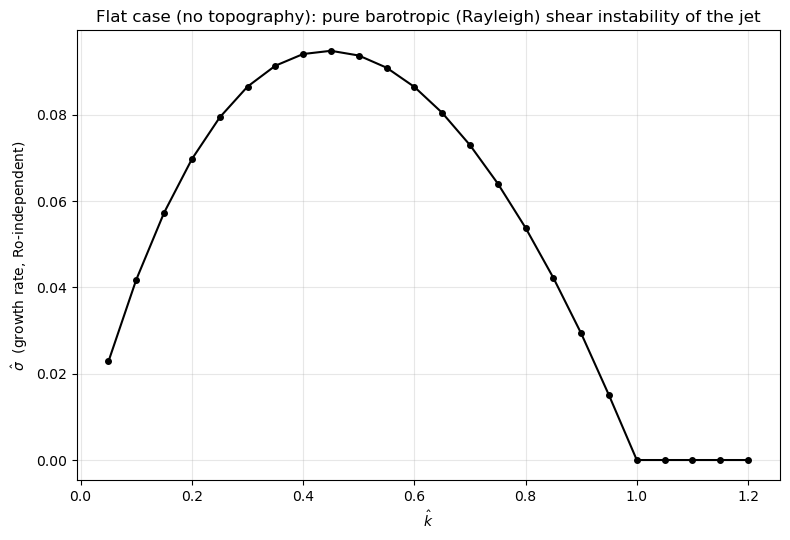

peak growth rate: 0.0948 at k=0.45
unstable for roughly k in [0.05, 0.95] (coarse -- refine ks_flat near the edges for a precise neutral cutoff)


In [10]:
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.plot(ks_flat, ref, 'k-o', markersize=4, linewidth=1.5)
ax.set_xlabel(r"$\hat k$")
ax.set_ylabel(r"$\hat\sigma$  (growth rate, Ro-independent)")
ax.set_title("Flat case (no topography): pure barotropic (Rayleigh) shear instability of the jet")
ax.grid(alpha=0.3)
fig.tight_layout(); plt.show()

k_peak_flat = ks_flat[np.argmax(ref)]
print(f"peak growth rate: {ref.max():.4f} at k={k_peak_flat:.2f}")
k_unstable = ks_flat[ref > 1e-6]
if k_unstable.size:
    print(f"unstable for roughly k in [{k_unstable.min():.2f}, {k_unstable.max():.2f}] "
          f"(coarse -- refine ks_flat near the edges for a precise neutral cutoff)")

### 3.3 Cross-validation against the Dickinson & Clare (1973) solver

`03_dickinson_clare_solver.ipynb` solves the same Rayleigh equation for $U(y)=\tfrac12(1+\tanh y)$,
$\beta=0$, with an independent method (4th-order Numerov, Newton iteration on the determinant).
Both profiles have $\Delta U=1$, so the growth rates should agree 1:1. The reference values below
were computed with that solver.

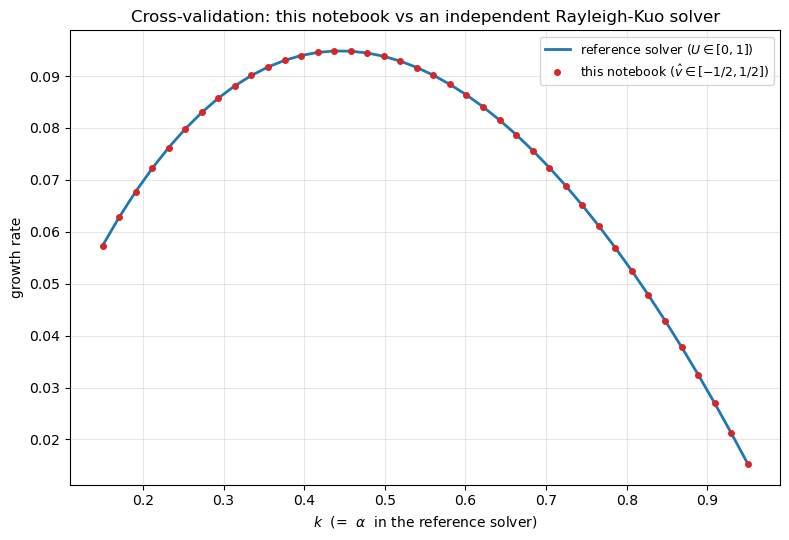

  alpha   ratio (ours/ref)
  0.150             0.9998
  0.232             0.9999
  0.314             0.9999
  0.396             0.9999
  0.478             0.9999
  0.560             0.9998
  0.642             0.9997
  0.724             0.9996
  0.806             0.9994
  0.888             0.9988

mean ratio = 0.9995  (predicted exactly 1.0 -- Delta-U matches, offset is irrelevant)


In [11]:
# reference solver's own alpha grid and omega_i = alpha*c_i, reproduced by running
# its exact code (4th-order Numerov + Newton iteration) for U = 0.5*(1+tanh(y))
alphas_ref = np.array([
    0.15000, 0.17051, 0.19103, 0.21154, 0.23205, 0.25256, 0.27308, 0.29359,
    0.31410, 0.33462, 0.35513, 0.37564, 0.39615, 0.41667, 0.43718, 0.45769,
    0.47821, 0.49872, 0.51923, 0.53974, 0.56026, 0.58077, 0.60128, 0.62179,
    0.64231, 0.66282, 0.68333, 0.70385, 0.72436, 0.74487, 0.76538, 0.78590,
    0.80641, 0.82692, 0.84744, 0.86795, 0.88846, 0.90897, 0.92949, 0.95000])
omega_i_ref = np.array([
    0.057324, 0.062773, 0.067728, 0.072209, 0.076234, 0.079822, 0.082990, 0.085752,
    0.088123, 0.090117, 0.091745, 0.093020, 0.093953, 0.094552, 0.094829, 0.094791,
    0.094447, 0.093805, 0.092872, 0.091655, 0.090161, 0.088395, 0.086363, 0.084070,
    0.081522, 0.078723, 0.075678, 0.072390, 0.068865, 0.065106, 0.061115, 0.056898,
    0.052456, 0.047792, 0.042911, 0.037814, 0.032504, 0.026983, 0.021254, 0.015319])

ours_on_ref_grid = growth_curve_general(alphas_ref, 1.0, 0.0, hs_flat, 0.0,
                                         Ljet_nd=1.0, dx=0.02, Ws_nd=1.0)

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.plot(alphas_ref, omega_i_ref, 'C0-', linewidth=2, label=r"reference solver ($U\in[0,1]$)")
ax.plot(alphas_ref, ours_on_ref_grid, 'C3o', markersize=4, label=r"this notebook ($\hat v\in[-1/2,1/2]$)")
ax.set_xlabel(r"$k$  (=  $\alpha$  in the reference solver)")
ax.set_ylabel(r"growth rate")
ax.set_title("Cross-validation: this notebook vs an independent Rayleigh-Kuo solver")
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
fig.tight_layout(); plt.show()

ratio = ours_on_ref_grid / omega_i_ref
print(f"{'alpha':>7s} {'ratio (ours/ref)':>18s}")
for a, r in zip(alphas_ref[::4], ratio[::4]):
    print(f"{a:7.3f} {r:18.4f}")
print(f"\nmean ratio = {ratio.mean():.4f}  (predicted exactly 1.0 -- Delta-U matches, offset is irrelevant)")

The ratio should be `1.0000` across nearly the whole curve.